# ESN and quantum reservoir: loss and MAE versus epoch

Edit **all experiment hyperparameters in the settings cell below**. This notebook
builds both reservoirs directly; its settings are independent of `main.py`.
Use the project's Python environment with `requirements_notebook.txt` installed.

Only `w_out` and its bias are trained with Adam, using the same training function
as `main.py`. Inputs and same-frame decision targets come from `final_dataset.pkl`.
Videos keep their individual lengths. Fixed reservoir features are cached once.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

# Locate src/ from the project root or any of its subdirectories.
PROJECT_DIR = next(path for path in (Path.cwd(), *Path.cwd().parents)
                   if (path / "src" / "reservoirs.py").is_file())
SRC_DIR = PROJECT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from reservoirs import ESNReservoir, QiskitQuantumReservoir
from utils import cached_metrics, make_loader, reservoir_features, train_readout
from video_data import load_dataset, split_video_indices

# Dataset, split, and optimization settings: edit everything here.
DATASET_PATH = SRC_DIR / "dataset" / "final_dataset.pkl"
SEED = 42
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15  # Test uses the remaining fraction.
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 1e-3
ADAM_BETAS = (0.9, 0.999)
ADAM_EPS = 1e-8

# All ESN constructor hyperparameters; input/output widths come from the data.
ESN_CONFIG = {
    "reservoir_size": 100,
    "leak_rate": 0.3,
    "spectral_radius": 0.9,
    "reservoir_connectivity": 1.0,
    "time_step": 1,
}

# All quantum constructor hyperparameters; damping is the quantum leak rate.
QUANTUM_CONFIG = {
    "num_qubits": 6,
    "hz": 1.0,
    "Jz": 10.0,
    "reservoir_time": 1.0,
    "interaction": "XX",
    "connectivity": "all_to_all",
    "single_observables": ("Z", "X"),
    "pair_observables": ("ZZ", "XX"),
    "damping": 0.3,
    "time_step": 1,
    "coupling_seed": 42,
}

# Reset seeds when rerunning the entire experiment.
torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"Dataset: {DATASET_PATH}")
print(f"Adam: epochs={EPOCHS}, learning_rate={LEARNING_RATE}, batch_size={BATCH_SIZE}")

Dataset: /Users/juanfrancisco/Desktop/hackathon/src/dataset/final_dataset.pkl
Adam: epochs=100, learning_rate=0.001, batch_size=64


## Load videos and build both reservoirs

Time-step lists are used to validate input/target alignment. Only each video's
`(frames_i, features)` and `(frames_i, decisions)` value arrays enter training.

In [2]:
X, y = load_dataset(DATASET_PATH, dtype=np.float32)
train_indices, val_indices, test_indices = split_video_indices(
    len(X), SEED, TRAIN_FRACTION, VAL_FRACTION
)
split_indices = {"train": train_indices, "validation": val_indices, "test": test_indices}
splits = {name: ([X[i] for i in indices], [y[i] for i in indices])
          for name, indices in split_indices.items()}

# Feature and decision widths are determined by the imported dataset.
dimensions = {"input_dim": X[0].shape[1], "output_dim": y[0].shape[1]}
model_configs = {"Classical ESN": {**ESN_CONFIG, **dimensions},
                 "Quantum": {**QUANTUM_CONFIG, **dimensions}}
models = {"Classical ESN": ESNReservoir(model_configs["Classical ESN"]),
          "Quantum": QiskitQuantumReservoir(**model_configs["Quantum"])}

print(f"Videos={len(X)}, frames={min(map(len, X))}..{max(map(len, X))}, "
      f"features={X[0].shape[1]}, decisions={y[0].shape[1]}")
print("Video splits:", {name: len(indices) for name, indices in split_indices.items()})
for name, model in models.items():
    print(f"{name}: {model.w_out.in_features} readout features; {model_configs[name]}")

Videos=100, frames=36..59, features=19, decisions=7
Video splits: {'train': 70, 'validation': 15, 'test': 15}
Classical ESN: 100 readout features; {'reservoir_size': 100, 'leak_rate': 0.3, 'spectral_radius': 0.9, 'reservoir_connectivity': 1.0, 'time_step': 1, 'input_dim': 19, 'output_dim': 7}
Quantum: 42 readout features; {'num_qubits': 6, 'hz': 1.0, 'Jz': 10.0, 'reservoir_time': 1.0, 'interaction': 'XX', 'connectivity': 'all_to_all', 'single_observables': ('Z', 'X'), 'pair_observables': ('ZZ', 'XX'), 'damping': 0.3, 'time_step': 1, 'coupling_seed': 42, 'input_dim': 19, 'output_dim': 7}


## Cache reservoir features

This is the reservoir simulation step. Each video's state resets independently.
The epoch loop below updates only the linear readouts, using these cached real frames.

In [3]:
feature_cache = {}
for name, model in models.items():
    feature_cache[name] = {}
    for split_name, (split_X, split_y) in splits.items():
        print(f"{name}: computing {split_name} reservoir features...", flush=True)
        videos = make_loader(split_X, split_y, BATCH_SIZE)
        cached = reservoir_features(model, videos, BATCH_SIZE)
        feature_cache[name][split_name] = cached
        features, targets = cached.dataset.tensors
        print(f"  Cached {len(features)} frames, {features.shape[1]} features", flush=True)

Classical ESN: computing train reservoir features...


  Cached 3299 frames, 100 features


Classical ESN: computing validation reservoir features...


  Cached 677 frames, 100 features


Classical ESN: computing test reservoir features...


...

  Cached 3299 frames, 42 features


Quantum: computing validation reservoir features...


  Cached 677 frames, 42 features


Quantum: computing test reservoir features...


  Cached 723 frames, 42 features


## Train the readouts and record metrics

Epoch 0 is the untrained baseline. Training and validation MSE and MAE are measured
**after** each complete epoch, averaging over every actual frame coordinate.
Adam minimizes MSE and updates only the readout weights and bias.

The readout with the lowest validation MSE is restored before scoring the test split
once. Histories and models stay in memory; no checkpoint or benchmark files are written.

`train_readout` is shared with `main.py` so both experiments use the same
Adam updates, epoch metrics, and validation selection. Every setting passed to
it is defined in this notebook's settings cell.

In [4]:
histories, results = {}, {}
for name, model in models.items():
    cache = feature_cache[name]
    # Verify that training never changes the fixed reservoir parameters.
    fixed_before = {key: value.clone() for key, value in model.state_dict().items()
                    if not key.startswith("w_out.")}
    fitted = train_readout(
        model, cache["train"], cache["validation"], epochs=EPOCHS,
        learning_rate=LEARNING_RATE, betas=ADAM_BETAS, eps=ADAM_EPS,
        seed=SEED, label=name,
    )
    assert all(torch.equal(model.state_dict()[key], value) for key, value in fixed_before.items())
    histories[name] = fitted["history"]
    results[name] = {"best_epoch": fitted["best_epoch"],
                     "validation_mse": fitted["validation"]["loss"],
                     "test": cached_metrics(model, cache["test"])}
    print(f"{name} | best epoch={fitted['best_epoch']} | "
          f"test MSE={results[name]['test']['loss']:.6f}, "
          f"MAE={results[name]['test']['mae']:.6f}", flush=True)

Classical ESN | epoch 0/100 | train loss (MSE)=0.198293 | train MAE=0.291548 | val loss (MSE)=0.196989 | val MAE=0.290655


Classical ESN | epoch 1/100 | train loss (MSE)=0.140267 | train MAE=0.210991 | val loss (MSE)=0.143359 | val MAE=0.215828


Classical ESN | epoch 2/100 | train loss (MSE)=0.119748 | train MAE=0.195499 | val loss (MSE)=0.121065 | val MAE=0.198618


Classical ESN | epoch 3/100 | train loss (MSE)=0.108313 | train MAE=0.187918 | val loss (MSE)=0.108407 | val MAE=0.190511


Classical ESN | epoch 4/100 | train loss (MSE)=0.0996199 | train MAE=0.176656 | val loss (MSE)=0.0995718 | val MAE=0.17933


...

Quantum | epoch 97/100 | train loss (MSE)=0.159971 | train MAE=0.226943 | val loss (MSE)=0.164592 | val MAE=0.234952


Quantum | epoch 98/100 | train loss (MSE)=0.15991 | train MAE=0.226415 | val loss (MSE)=0.164575 | val MAE=0.234879


Quantum | epoch 99/100 | train loss (MSE)=0.159865 | train MAE=0.226131 | val loss (MSE)=0.164404 | val MAE=0.234156


Quantum | epoch 100/100 | train loss (MSE)=0.159774 | train MAE=0.226962 | val loss (MSE)=0.164455 | val MAE=0.235319


Quantum | best epoch=99 | test MSE=0.164944, MAE=0.228784


## Epoch curves

Solid lines show training metrics; dashed lines show validation metrics.
All recorded epochs are plotted, including the initial baseline at epoch 0.
The final models in `models` use their best validation epoch.

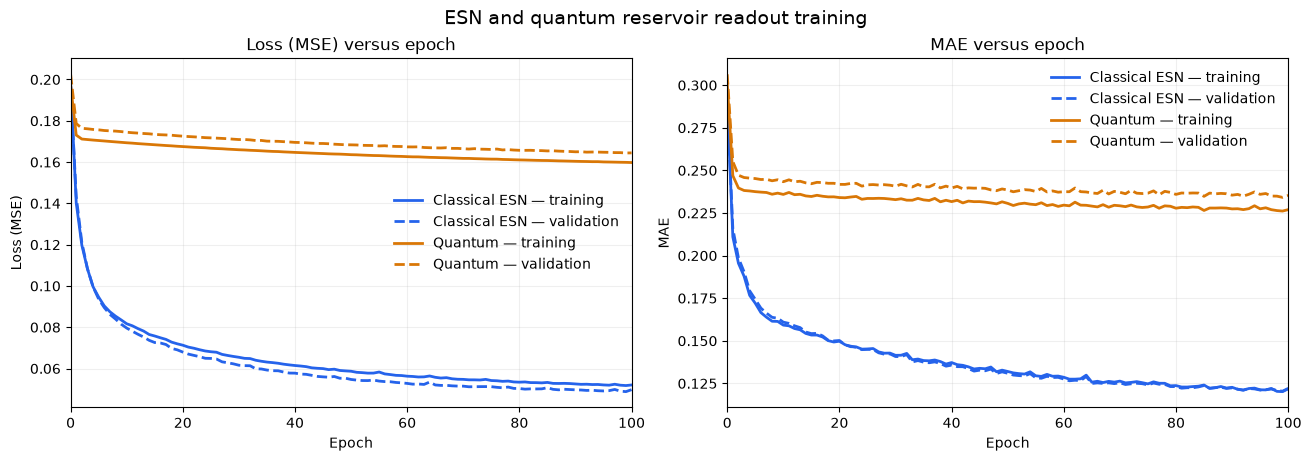

In [5]:
colors = {"Classical ESN": "#2563EB", "Quantum": "#D97706"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, metric, title in zip(axes, ("loss", "mae"), ("Loss (MSE)", "MAE")):
    for name, history in histories.items():
        for split, style in (("train", "-"), ("val", "--")):
            ax.plot(history["epoch"], history[f"{split}_{metric}"],
                    color=colors[name], linestyle=style, linewidth=2,
                    label=f"{name} — {'training' if split == 'train' else 'validation'}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(f"{title} versus epoch")
    ax.set_xlim(0, EPOCHS)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle("ESN and quantum reservoir readout training", fontsize=14)
plt.show()

In [6]:
print(f"{'Model':<18} {'Best epoch':>10} {'Val MSE':>12} {'Test MSE':>12} {'Test MAE':>12}")
for name, scores in results.items():
    print(f"{name:<18} {scores['best_epoch']:>10} {scores['validation_mse']:>12.6f} "
          f"{scores['test']['loss']:>12.6f} {scores['test']['mae']:>12.6f}")

Model              Best epoch      Val MSE     Test MSE     Test MAE
Classical ESN              99     0.048816     0.058002     0.127545
Quantum                    99     0.164404     0.164944     0.228784
